# Dataset Description

For this assignment, I used the Chesapeake Bay Program water quality dataset from 2021–2026, collected at station 4.1C in the upper mainstem Chesapeake Bay. The dataset contains surface water measurements for different water quality parameters. I used this dataset to explore the variables and compare three regression models.

In [1]:
%matplotlib inline

# Import libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random

# Linear model and basic functions from scikit-learn
from sklearn import datasets, linear_model
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Specific regression models from scikit-learn
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import RadiusNeighborsRegressor

from pathlib import Path

In [2]:
# load in the Chesapeake Bay water quality dataset
infile = '../data/CBP_TWQM_MAIN_WQ_2021_2026_surface.csv'

# read in the .csv file with the column separator explicitly defined
data = pd.read_csv(infile, sep=',', low_memory=False)

# display column names
data.columns

Index(['Station', 'FieldActivityId', 'Cruise', 'Program', 'Project',
       'DataCollector', 'DataProvider', 'Latitude', 'Longitude', 'SampleDate',
       'SampleTime', 'TotalDepthM', 'UpperPycnoclineDepthM',
       'LowerPycnoclineDepthM', 'SampleDepthM', 'Layer', 'SampleType',
       'SampleReplicate', 'Parameter', 'Qualifier', 'MeasureValue',
       'MeasureUnit', 'Method', 'Lab', 'Problem', 'PrecisionPC', 'BiasPC',
       'Details', 'TierLevel'],
      dtype='str')

### 1. Data Exploration and Preparation

Before applying regression models, I first explored the Chesapeake Bay water quality dataset to understand its structure and check for possible data quality issues. I looked at the variables, missing values, and number of observations for each parameter. This will help me select appropriate variables and prepare the data for regression analysis.

In [3]:
# display the different water quality parameters
data['Parameter'].unique()

<StringArray>
[    'CHLA',      'DIN',       'DO',      'DON',      'DOP',       'KD',
     'NH4F',    'NO23F',     'NO2F',     'NO3F',       'PC',       'PH',
     'PHEO',       'PN',     'PO4F',       'PP', 'SALINITY',   'SECCHI',
  'SIGMA_T',   'SPCOND',      'TDN',      'TDP',       'TN',      'TON',
       'TP',      'TSS',    'WTEMP']
Length: 27, dtype: str

In [4]:
# check the size of the dataset
data.shape

(1223, 29)

In [5]:
# display the first five rows
data.head()

,Station,FieldActivityId,Cruise,Program,Project,DataCollector,DataProvider,Latitude,Longitude,SampleDate,...,Qualifier,MeasureValue,MeasureUnit,Method,Lab,Problem,PrecisionPC,BiasPC,Details,TierLevel
0,CB4.1C,785801,BAY900,TWQM,MAIN,MDDNR,MDDNR,38.82593,-76.39945,2025-11-18,...,NaN,11.000,UG/L,L01,CBL,NaN,NaN,NaN,NaN,T3
1,CB4.1C,785781,BAY898,TWQM,MAIN,MDDNR,MDDNR,38.82593,-76.39945,2025-10-06,...,NaN,7.049,UG/L,L01,CBL,NaN,NaN,NaN,NaN,T3
2,CB4.1C,785724,BAY895,TWQM,MAIN,MDDNR,MDDNR,38.82593,-76.39945,2025-08-26,...,NaN,7.156,UG/L,L01,CBL,NaN,NaN,NaN,NaN,T3
3,CB4.1C,785723,BAY894,TWQM,MAIN,MDDNR,MDDNR,38.82593,-76.39945,2025-08-06,...,NaN,15.620,UG/L,L01,CBL,NaN,NaN,NaN,NaN,T3
4,CB4.1C,785680,BAY893,TWQM,MAIN,MDDNR,MDDNR,38.82593,-76.39945,2025-07-21,...,NaN,38.662,UG/L,L01,CBL,NaN,NaN,NaN,NaN,T3


In [6]:
# check data types and missing values
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1223 entries, 0 to 1222
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Station                1223 non-null   str    
 1   FieldActivityId        1223 non-null   int64  
 2   Cruise                 1223 non-null   str    
 3   Program                1223 non-null   str    
 4   Project                1223 non-null   str    
 5   DataCollector          1223 non-null   str    
 6   DataProvider           1223 non-null   str    
 7   Latitude               1223 non-null   float64
 8   Longitude              1223 non-null   float64
 9   SampleDate             1223 non-null   str    
 10  SampleTime             1223 non-null   str    
 11  TotalDepthM            1223 non-null   float64
 12  UpperPycnoclineDepthM  1022 non-null   float64
 13  LowerPycnoclineDepthM  1022 non-null   float64
 14  SampleDepthM           1223 non-null   float64
 15  Layer          

In [7]:
# count observations for each water quality parameter
data['Parameter'].value_counts()

Parameter
DOP         70
DIN         60
DON         60
TON         60
NO3F        49
CHLA        42
DO          42
KD          42
NH4F        42
NO23F       42
NO2F        42
PC          42
PH          42
PHEO        42
PN          42
PO4F        42
PP          42
SALINITY    42
SECCHI      42
SIGMA_T     42
SPCOND      42
TDN         42
TDP         42
TN          42
TP          42
TSS         42
WTEMP       42
Name: count, dtype: int64

In [8]:
# check missing values in each column
data.isnull().sum()

Station                     0
FieldActivityId             0
Cruise                      0
Program                     0
Project                     0
DataCollector               0
DataProvider                0
Latitude                    0
Longitude                   0
SampleDate                  0
SampleTime                  0
TotalDepthM                 0
UpperPycnoclineDepthM     201
LowerPycnoclineDepthM     201
SampleDepthM                0
Layer                       0
SampleType                  0
SampleReplicate             0
Parameter                   0
Qualifier                 992
MeasureValue                0
MeasureUnit                 0
Method                      0
Lab                       336
Problem                  1199
PrecisionPC              1223
BiasPC                   1223
Details                  1223
TierLevel                   0
dtype: int64

In [9]:
# check measurement qualifiers
data['Qualifier'].value_counts(dropna=False)

Qualifier
NaN    992
<      231
Name: count, dtype: int64

In [10]:
# check which parameters have qualified measurements
data[data['Qualifier'] == '<']['Parameter'].value_counts()

Parameter
DOP      56
DIN      36
DON      36
TON      36
PO4F     28
NH4F     16
NO3F     14
NO2F      5
NO23F     2
PHEO      2
Name: count, dtype: int64

In [11]:
# check repeated measurements for the same sampling event
data.duplicated(
    subset=['SampleDate', 'SampleTime', 'Parameter']
).sum()

np.int64(89)

In [12]:
# examine repeated measurements
duplicates = data[
    data.duplicated(
        subset=['SampleDate', 'SampleTime', 'Parameter'],
        keep=False
    )
]

duplicates[
    ['SampleDate', 'SampleTime', 'Parameter',
     'SampleReplicate', 'MeasureValue']
].head(20)

,SampleDate,SampleTime,Parameter,SampleReplicate,MeasureValue
43,2025-10-06,12:29:00,DIN,S1,0.0172
44,2025-10-06,12:29:00,DIN,S1,0.0127
45,2025-08-26,12:27:00,DIN,S1,0.0147
46,2025-08-26,12:27:00,DIN,S1,0.0102
47,2025-08-06,12:20:00,DIN,S1,0.0211
48,2025-08-06,12:20:00,DIN,S1,0.0166
49,2025-07-21,12:50:00,DIN,S1,0.0130
50,2025-07-21,12:50:00,DIN,S1,0.0085
53,2025-02-04,10:09:00,DIN,S1,0.1198
54,2025-02-04,10:09:00,DIN,S1,0.1153


In [13]:
# examine additional information about repeated measurements
duplicates[
    ['SampleDate', 'SampleTime', 'Parameter',
     'Method', 'Lab', 'Qualifier', 'MeasureValue']
].head(20)

,SampleDate,SampleTime,Parameter,Method,Lab,Qualifier,MeasureValue
43,2025-10-06,12:29:00,DIN,D01A,CBL,<,0.0172
44,2025-10-06,12:29:00,DIN,D01B,CBL,<,0.0127
45,2025-08-26,12:27:00,DIN,D01A,CBL,<,0.0147
46,2025-08-26,12:27:00,DIN,D01B,CBL,<,0.0102
47,2025-08-06,12:20:00,DIN,D01A,CBL,<,0.0211
48,2025-08-06,12:20:00,DIN,D01B,CBL,<,0.0166
49,2025-07-21,12:50:00,DIN,D01A,CBL,<,0.0130
50,2025-07-21,12:50:00,DIN,D01B,CBL,<,0.0085
53,2025-02-04,10:09:00,DIN,D01A,CBL,<,0.1198
54,2025-02-04,10:09:00,DIN,D01B,CBL,<,0.1153


In [14]:
# check repeated measurements for selected regression variables
selected = ['DO', 'CHLA', 'TN', 'TP', 'WTEMP', 'SALINITY']

data[data['Parameter'].isin(selected)].groupby(
    ['SampleDate', 'SampleTime', 'Parameter']
).size().value_counts()

1    252
Name: count, dtype: int64

In [15]:
# check whether selected parameters were measured at the same time
selected = ['DO', 'CHLA', 'TN', 'TP', 'WTEMP', 'SALINITY']

data[data['Parameter'].isin(selected)].groupby(
    ['SampleDate', 'SampleTime']
)['Parameter'].nunique().value_counts()

Parameter
6    42
Name: count, dtype: int64

In [16]:
# reshape selected water quality parameters into columns
selected = ['DO', 'CHLA', 'TN', 'TP', 'WTEMP', 'SALINITY']

regression_data = data[data['Parameter'].isin(selected)].pivot(
    index=['SampleDate', 'SampleTime'],
    columns='Parameter',
    values='MeasureValue'
)

# display the first five rows
regression_data.head()

,Parameter,CHLA,DO,SALINITY,TN,TP,WTEMP
SampleDate,SampleTime,,,,,,
2021-10-05,12:47:00,7.595,7.3,8.31,0.747,0.0346,23.3
2021-11-17,11:57:00,17.444,10.4,9.33,0.922,0.0486,12.8
2021-12-08,12:05:00,12.935,10.2,11.87,0.736,0.0282,9.2
2022-03-15,13:29:00,20.292,11.9,9.33,1.072,0.0243,6.6
2022-04-12,12:42:00,29.904,11.4,8.50,1.104,0.0357,10.3


In [17]:
# check the size and missing values of the regression dataset
print(regression_data.shape)
print(regression_data.isnull().sum())

(42, 6)
Parameter
CHLA        0
DO          0
SALINITY    0
TN          0
TP          0
WTEMP       0
dtype: int64


### EDA Findings and Data Preparation

The original dataset contains 1,223 rows, 29 columns, and 27 water quality parameters. During the initial exploration, I found that some columns had missing values, but the `MeasureValue` column had no missing observations. I also noticed that 231 measurements had a `<` qualifier, mainly for some nutrient parameters.

Another thing I found was that some parameters had repeated measurements on the same date and time. After checking further, I noticed that some of these measurements used different method codes. Therefore, I did not remove them without knowing the reason.

For regression, I selected six variables: dissolved oxygen (DO), chlorophyll-a (CHLA), total nitrogen (TN), total phosphorus (TP), water temperature (WTEMP), and salinity (SALINITY). I reshaped the data so that each parameter became a separate column. The final dataset has 42 observations and six variables, with no missing values.

I will use dissolved oxygen as the target variable and the remaining five variables as predictors to compare three regression models.

## 2. Regression Models

### Target and Predictor Variables

For this assignment, I selected dissolved oxygen (DO) as the target variable because it is an important indicator of water quality. I selected chlorophyll-a (CHLA), total nitrogen (TN), total phosphorus (TP), water temperature (WTEMP), and salinity (SALINITY) as predictors because these variables may be related to oxygen conditions in the water.

I will compare three regression models: Multiple Linear Regression, K-Nearest Neighbors (KNN), and Multi-Layer Perceptron (MLP). I will use 80% of the observations for training and 20% for testing, following the approach used in class.

In [18]:
# select input variables and target variable
X = regression_data[['CHLA', 'TN', 'TP', 'WTEMP', 'SALINITY']]
y = regression_data['DO']

# split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=4
)

# check the number of observations
print("Training observations:", X_train.shape[0])
print("Testing observations:", X_test.shape[0])

Training observations: 33
Testing observations: 9


### 2.1 Multiple Linear Regression

I first used multiple linear regression to predict dissolved oxygen
using the five selected water quality variables.

In [19]:
# create and train the linear regression model
regr = linear_model.LinearRegression()
regr.fit(X_train, y_train)

# predict dissolved oxygen using the test data
y_pred_lr = regr.predict(X_test)

# calculate the R2 score
r2_lr = r2_score(y_test, y_pred_lr)

print("R2 score:", r2_lr)

R2 score: 0.6053854128812612


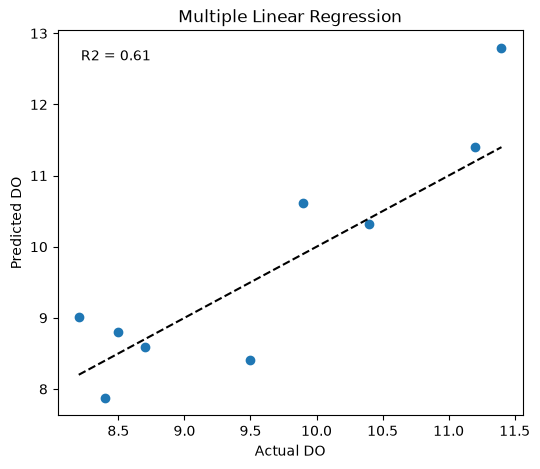

In [20]:
# plot actual vs predicted dissolved oxygen
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred_lr)

# add reference line for perfect predictions
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], 'k--')

plt.xlabel('Actual DO')
plt.ylabel('Predicted DO')
plt.title('Multiple Linear Regression')
plt.text(0.05, 0.95, 'R2 = {:.2f}'.format(r2_lr),
         transform=plt.gca().transAxes, va='top')

plt.show()

**Multiple Linear Regression Results**

The multiple linear regression model produced an R² score of 0.605 (approximately 0.61) on the testing data. This means the model explained about 60.5% of the variation in dissolved oxygen values. In the scatter plot, some predicted values are close to the dashed line, while others are farther away, showing differences between actual and predicted values. Since the testing dataset contains only nine observations, the results should be interpreted carefully.

### 2.2 K-Nearest Neighbors (KNN) Regression

For the second model, I used K-Nearest Neighbors (KNN) regression to predict dissolved oxygen. Unlike linear regression, KNN makes predictions based on observations with similar predictor values. I started with k = 3, meaning the model uses the three nearest training observations to make a prediction.

Since the predictor variables have different scales, I standardized them before fitting the KNN model.

In [24]:
# compare different values of k using training data
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

for k in [2, 3, 4, 5, 6, 7]:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(n_neighbors=k)
    )

    scores = cross_val_score(
        model, X_train, y_train, cv=5, scoring='r2'
    )

    print("k =", k, "Mean CV R2 =", round(scores.mean(), 3))

k = 2 Mean CV R2 = 0.374
k = 3 Mean CV R2 = 0.508
k = 4 Mean CV R2 = 0.528
k = 5 Mean CV R2 = 0.514
k = 6 Mean CV R2 = 0.485
k = 7 Mean CV R2 = 0.453


In [25]:
# import StandardScaler
from sklearn.preprocessing import StandardScaler

# standardize the predictor variables
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# choose the number of neighbors
k = 4

# create and train the KNN regression model
knn = KNeighborsRegressor(n_neighbors=k)
knn.fit(X_train_scaled, y_train)

# predict dissolved oxygen
y_pred_knn = knn.predict(X_test_scaled)

# calculate R2 score
r2_knn = r2_score(y_test, y_pred_knn)

print("KNN R2 score:", r2_knn)

KNN R2 score: 0.38119772304832733


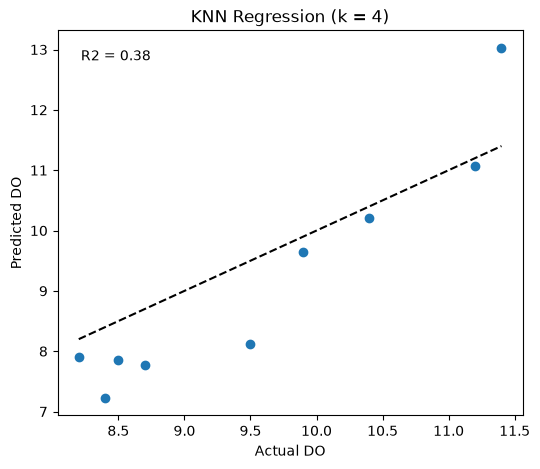

In [26]:
# plot actual vs predicted dissolved oxygen
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred_knn)

# add reference line for perfect predictions
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], 'k--')

plt.xlabel('Actual DO')
plt.ylabel('Predicted DO')
plt.title('KNN Regression (k = 4)')
plt.text(0.05, 0.95, 'R2 = {:.2f}'.format(r2_knn),
         transform=plt.gca().transAxes, va='top')

plt.show()

**KNN Regression Results and Hyperparameter Selection**

I initially used k = 3 for KNN regression. I then tested different values of k from 2 to 7 using five-fold cross-validation on the training data. Among these values, k = 4 had the highest average cross-validation R² score (0.528). Therefore, I selected k = 4 for the final model.

The final KNN model produced an R² score of 0.381 on the testing data. The scatter plot shows that some predicted values are close to the dashed line, while others are farther away. Compared with multiple linear regression (R² = 0.605), KNN performed less well on the testing data.

### 2.3 Multi-Layer Perceptron (MLP) Regression

For the third model, I used Multi-Layer Perceptron (MLP) regression to predict dissolved oxygen. MLP is a neural network model that can learn non-linear relationships between variables. I started with one hidden layer containing five neurons because the dataset is relatively small. I used the standardized predictor variables for this model.

In [28]:
# create the MLP regression model
mlp = MLPRegressor(
    hidden_layer_sizes=(5,),
    solver='lbfgs',
    max_iter=2000,
    random_state=4
)
# train the model
mlp.fit(X_train_scaled, y_train)

# predict dissolved oxygen
y_pred_mlp = mlp.predict(X_test_scaled)

# calculate R2 score
r2_mlp = r2_score(y_test, y_pred_mlp)

print("MLP R2 score:", r2_mlp)

MLP R2 score: 0.13876280683672215


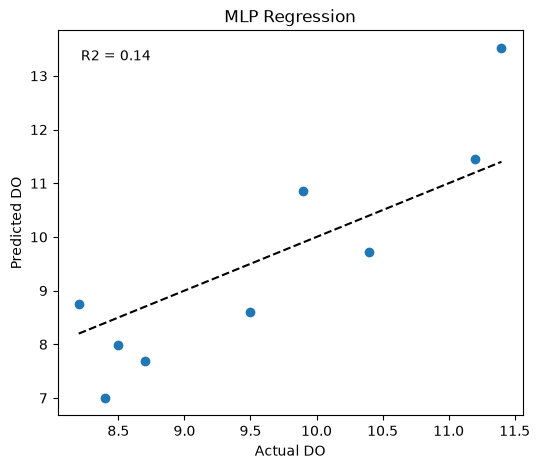

In [29]:
# plot actual vs predicted dissolved oxygen
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred_mlp)

# add reference line for perfect predictions
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], 'k--')

plt.xlabel('Actual DO')
plt.ylabel('Predicted DO')
plt.title('MLP Regression')
plt.text(0.05, 0.95, 'R2 = {:.2f}'.format(r2_mlp),
         transform=plt.gca().transAxes, va='top')

plt.show()

**MLP Regression Results and Hyperparameters**

I used one hidden layer with five neurons for the MLP model because the dataset is relatively small. Initially, I used the default optimizer, but the model did not converge after 2,000 iterations and produced a negative R² score. I then used the `lbfgs` solver, which ran without a convergence warning.

The final MLP model produced an R² score of 0.139 on the testing data. The scatter plot shows that some predicted values are close to the dashed line, while others are farther away. Compared with multiple linear regression and KNN, the MLP model had the lowest R² score on the testing data.

## 3. Model Comparison and Conclusion

I compared three regression models to predict dissolved oxygen using five water quality variables. Multiple linear regression had the highest R² score (0.605), followed by KNN (0.381) and MLP (0.139).

Based on these results, multiple linear regression performed best on the testing dataset. This suggests that a simpler linear model worked better than the two non-linear models for these observations. However, the dataset contains only 42 observations, with nine used for testing, so the results may change with more data or a different training and testing split.